# Figure S5 - Global conformational properties of DDX4<sup>[1-245]</sup> from STARLING ensembles

**What the figure shows.** Two panels describing how the size and shape of the chain co-vary across a STARLING-generated ensemble of 6,000 conformers: **(A)** radius of gyration ($R_g$) against asphericity, and **(B)** hydrodynamic radius ($R_h$) against asphericity, with the experimental DLS value (42 Angstroms) marked. Both are two-dimensional histograms in absolute counts, with kernel density estimate contours overlaid as a visual guide.

**This is Figure S4 repeated with a completely different method.** Figure S4 is the same analysis on all-atom Monte Carlo simulations, which take about a month of compute per system. STARLING is a deep-learning generative model that predicts conformational ensembles of disordered regions directly from sequence in minutes on a laptop. The two figures should be read side by side: if a cheap sequence-based predictor and an expensive physics-based simulation agree with each other *and* with the experiment, the resulting conformational picture is much harder to dismiss as an artefact of either method.

They do agree. STARLING gives a mean $R_g$ of 41.7 Angstroms and a mean $R_h$ of 41.4 Angstroms, against 45.9 and 44.0 from the all-atom simulations, and 42 Angstroms from DLS. The distributions have the same broad, diagonally elongated shape - larger conformations are also more elongated - which is the signature of a well-sampled disordered chain rather than a folded protein.

**How it is made.** Ensembles were generated with STARLING 1.0.0 using the VAE/U-Net implementation with DDPM weights, and analysed with the [STARLING](https://github.com/idptools/starling) package. $R_g$ and $R_h$ come from the STARLING ensemble object directly; asphericity needs three-dimensional coordinates and so is computed from the reconstructed ensemble trajectory with [SOURSOP](https://soursop.readthedocs.io/).

## What is in this directory

| path | contents |
|------|----------|
| `figures/` | output; the notebook writes one PDF and PNG per panel |

This figure has no data files of its own. It reads the wild-type STARLING ensemble (~1.5 GB) from the shared `data/` directory at the root of `perets_2025`, which is **not tracked by git** - see [`../data/README.md`](../data/README.md) for what belongs there, how it was generated, and how to obtain it.

## Setup

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Holehouse lab figure defaults (December 2024)
# ---------------------------------------------------------------------------

# export PDF/PS fonts as TrueType so text stays editable in Illustrator/Affinity
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

matplotlib.rcParams['axes.linewidth'] = 0.5
matplotlib.rcParams['lines.linewidth'] = 0.8

matplotlib.rcParams['xtick.major.size'] = 2
matplotlib.rcParams['xtick.minor.size'] = 0.5
matplotlib.rcParams['ytick.major.size'] = 2
matplotlib.rcParams['ytick.minor.size'] = 0.5
matplotlib.rcParams['xtick.major.width'] = 0.375
matplotlib.rcParams['ytick.major.width'] = 0.375
matplotlib.rcParams['xtick.minor.width'] = 0.375
matplotlib.rcParams['ytick.minor.width'] = 0.375
matplotlib.rcParams['xtick.major.pad'] = 1
matplotlib.rcParams['ytick.major.pad'] = 1

matplotlib.rcParams['xtick.labelsize'] = 8
matplotlib.rcParams['ytick.labelsize'] = 8
matplotlib.rcParams['axes.labelsize'] = 10
matplotlib.rcParams['legend.fontsize'] = 8

# The manuscript figures used Arial; the fallbacks let this run anywhere.
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from starling import load_ensemble
from soursop.sstrajectory import SSTrajectory

In [2]:
import os

DATA_DIR = os.environ.get('PERETS_DATA_DIR', '../data')
STARLING_DIR = os.path.join(DATA_DIR, 'starling')

os.makedirs('figures', exist_ok=True)

ENSEMBLE = os.path.join(STARLING_DIR, 'ddx4_wt_6000.starling')
TRAJECTORY = os.path.join(STARLING_DIR, 'ddx4_wt_6000.xtc')
TOPOLOGY = os.path.join(STARLING_DIR, 'ddx4_wt_6000.pdb')

for label, path in [('ensemble', ENSEMBLE), ('trajectory', TRAJECTORY), ('topology', TOPOLOGY)]:
    status = 'found' if os.path.isfile(path) else 'MISSING - see ../data/README.md'
    print(f'{label:<11} {path}  [{status}]')

ensemble    ../data/starling/ddx4_wt_6000.starling  [found]
trajectory  ../data/starling/ddx4_wt_6000.xtc  [found]
topology    ../data/starling/ddx4_wt_6000.pdb  [found]


## Load the ensemble

`load_ensemble` reads a `.starling` file, which stores the ensemble as a stack of inter-residue distance maps plus the reconstructed three-dimensional structures. Most scalar properties - including $R_g$ and $R_h$ - can be computed from the distance maps alone, which is why they come back essentially instantly.

In [3]:
DDX4 = load_ensemble(ENSEMBLE)

print(f'{len(DDX4):,} conformers, sequence length {len(DDX4.sequence)}')

6,000 conformers, sequence length 245


In [4]:
rg = DDX4.radius_of_gyration()
rh = DDX4.hydrodynamic_radius()      # default mode is the Nygaard et al. estimator

print(f'Rg : mean {np.mean(rg):.2f} A   range {np.min(rg):.1f} - {np.max(rg):.1f}')
print(f'Rh : mean {np.mean(rh):.2f} A   range {np.min(rh):.1f} - {np.max(rh):.1f}   (DLS: 42 A)')

Rg : mean 41.66 A   range 22.3 - 95.8
Rh : mean 41.42 A   range 28.1 - 61.8   (DLS: 42 A)


### Asphericity

Asphericity describes shape rather than size, so unlike $R_g$ and $R_h$ it cannot be recovered from a distance map - it needs the gyration tensor, and therefore actual three-dimensional coordinates. We compute it with SOURSOP from the reconstructed ensemble trajectory that STARLING wrote alongside the `.starling` file.

(The ensemble object does expose a `.trajectory` attribute, but calling SOURSOP's gyration-tensor code on that topology currently fails on an `mdtraj` attribute mismatch, so we read the trajectory files directly - which is what the original analysis did.)

In [5]:
starling_traj = SSTrajectory(TRAJECTORY, TOPOLOGY).proteinTrajectoryList[0]
asph = starling_traj.get_asphericity()

print(f'{starling_traj.n_frames:,} frames, {starling_traj.n_residues} residues')
print(f'asphericity : mean {np.mean(asph):.3f}  range {np.min(asph):.2f} - {np.max(asph):.2f}')

assert len(asph) == len(rg), 'trajectory and ensemble must describe the same conformers'

STATUS: Computing gyration tensor for 6000 frames


6,000 frames, 245 residues
asphericity : mean 0.397  range 0.01 - 0.93


## The panels

Both panels are built identically: a 50x50 two-dimensional histogram in absolute counts, so the colourbar reads directly as "how many conformations landed in this bin", with seaborn KDE contours on top purely as a visual guide to the shape of the distribution.

Note the bin count differs from Figure S4, which used 75 bins - that figure describes 25,000 conformers, this one 6,000, and the coarser binning keeps the counts per bin comparable.

In [6]:
# white -> navy, so that empty bins vanish into the background
white_to_blue = LinearSegmentedColormap.from_list('white_to_blue', ['white', 'navy'])


def density_contour_panel(x, y, xlabel, outfile, experimental_value=None, bins=50):
    """
    Draw a 2D histogram of two conformational properties with KDE contours.

    Produces one panel of Figure S5: an absolute-count 2D histogram with
    kernel density estimate contours overlaid for visual clarity, and an
    optional vertical line marking an experimentally measured value.

    Parameters
    ----------
    x : numpy.ndarray
        Per-conformer values for the x-axis (a radius, in Angstroms).

    y : numpy.ndarray
        Per-conformer values for the y-axis (asphericity).

    xlabel : str
        Axis label for the x-axis.

    outfile : str
        Path stem (without extension); both a PDF and a PNG are written.

    experimental_value : float or None
        If given, a vertical line is drawn here and labelled as the
        experimental DLS measurement. Default = None.

    bins : int
        Number of bins along each axis of the 2D histogram. Default = 50.

    Returns
    -------
    None
    """

    fig, ax = plt.subplots(figsize=(4.5, 4))

    hb = ax.hist2d(x, y, bins=bins, cmap=white_to_blue, density=False)

    # contours are a visual guide only - they carry no extra information
    sns.kdeplot(x=x, y=y, levels=12, linewidths=0.3, color='k', ax=ax)

    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel('Asphericity', fontsize=12)

    cbar = fig.colorbar(hb[3], ax=ax)
    cbar.set_label('Count', fontsize=12)

    if experimental_value is not None:
        ax.axvline(experimental_value, color='k', lw=1.3, ls='-',
                   label='Experimental value (DLS)')
        ax.legend(frameon=False)

    ax.set_facecolor('white')
    fig.patch.set_facecolor('white')
    ax.tick_params(labelsize=10)
    plt.tight_layout()

    plt.savefig(f'{outfile}.pdf')
    plt.savefig(f'{outfile}.png', dpi=350)
    plt.show()

### Panel A - radius of gyration versus asphericity

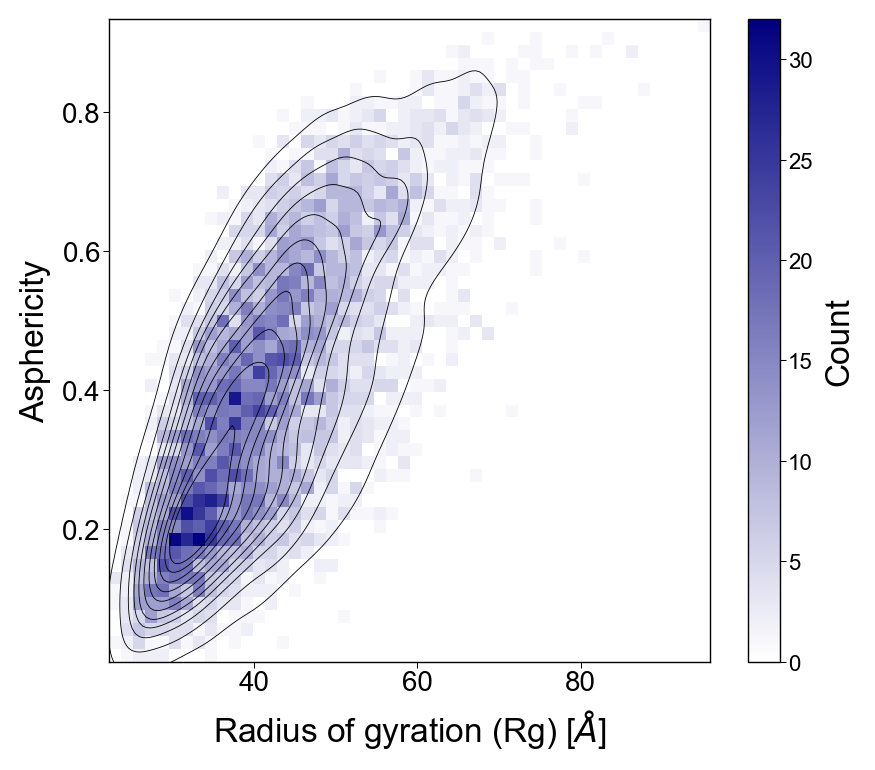

mean Rg = 41.7 A   (all-atom, Figure S4: 45.9 A)


In [7]:
density_contour_panel(rg, asph,
                      xlabel='Radius of gyration (Rg) [$\\AA$]',
                      outfile='figures/figure_S5A_rg_asphericity')

print(f'mean Rg = {np.mean(rg):.1f} A   (all-atom, Figure S4: 45.9 A)')

### Panel B - hydrodynamic radius versus asphericity

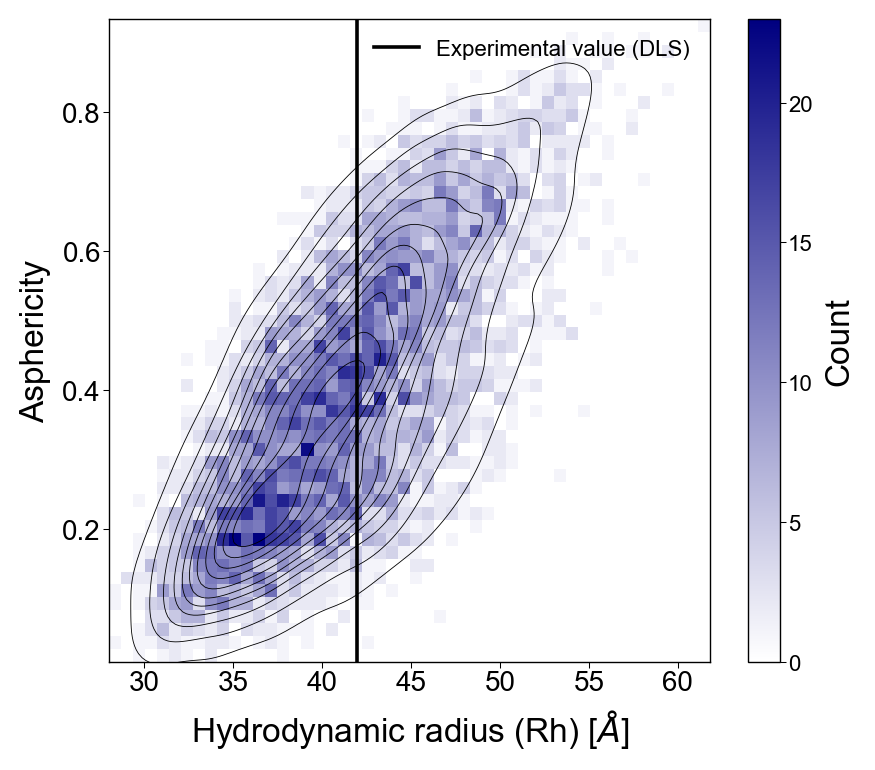

mean Rh = 41.4 A   (all-atom, Figure S4: 44.0 A;  DLS: 42 A)


In [8]:
density_contour_panel(rh, asph,
                      xlabel='Hydrodynamic radius (Rh) [$\\AA$]',
                      outfile='figures/figure_S5B_rh_asphericity',
                      experimental_value=42)

print(f'mean Rh = {np.mean(rh):.1f} A   (all-atom, Figure S4: 44.0 A;  DLS: 42 A)')

## Differences from the published figure

* **Assembly and labelling.** The published Figure S5 was assembled in a vector graphics editor from the two panel exports; the A and B letters were added there.
* **Asphericity is computed, not inherited.** In the original notebook the line that computed asphericity was commented out, and the variable was left over in the kernel from an earlier session - so the notebook as saved would not have run from a clean start. Here it is computed explicitly from the reconstructed trajectory, with an assertion that the conformer counts match.
* **Shared code between the panels.** The original had the plotting code written out twice, once per panel; here it is one function called twice, so the two panels are guaranteed to be styled identically.